# Optimización matemática: método del gradiente descendente

**Notebook didáctico e interactivo para Jupyter Notebook y Google Colab**

**Objetivos de aprendizaje**

1. Comprender los conceptos de función de costo, derivada, gradiente, tasa de aprendizaje y convergencia.
2. Resolver un ejercicio **analíticamente** mediante derivadas y búsqueda de puntos críticos.
3. Aplicar el **gradiente descendente**, mostrando el cálculo y las iteraciones.
4. Introducir funciones propias de **una o varias variables**, con valores iniciales y parámetros configurables.
5. Comparar soluciones y visualizar el comportamiento del algoritmo.

> **Alcance:** se estudia optimización **sin restricciones** de funciones reales **diferenciables** escritas de forma explícita. No existe un algoritmo de gradiente descendente que garantice resolver *cualquier* problema de optimización. En funciones no convexas puede encontrar mínimos locales; una solución analítica exacta puede no existir o no ser accesible. Las restricciones, discontinuidades y problemas discretos requieren otras técnicas.

## 1. Fundamentos de optimización

La **optimización** busca valores de las variables de decisión que produzcan el mejor resultado de una función objetivo. Es posible:

- **Minimizar:** encontrar $\min_{\mathbf{x}} f(\mathbf{x})$; por ejemplo, reducir el error en un modelo de inteligencia artificial.
- **Maximizar:** encontrar $\max_{\mathbf{x}} f(\mathbf{x})$; por ejemplo, aumentar una utilidad. Para maximizar mediante descenso, se puede minimizar $-f(\mathbf{x})$.

En aprendizaje automático, la función objetivo suele llamarse **función de costo o pérdida** $J(\mathbf{w})$. Los parámetros $\mathbf{w}$ pueden ser los pesos y sesgos de una red neuronal. El algoritmo intenta reducir esa pérdida ajustando los parámetros.

**Conceptos importantes**

| Concepto | Significado |
|---|---|
| Variable $x$ o vector $\mathbf{x}$ | Valor o conjunto de valores que queremos mejorar. |
| Función objetivo $f$ | Magnitud que queremos minimizar. |
| Derivada $f'(x)$ | Pendiente de la función cuando existe una sola variable. |
| Gradiente $\nabla f(\mathbf{x})$ | Vector de derivadas parciales que señala la dirección de mayor aumento local. |
| Tasa de aprendizaje $\alpha$ (o $\beta$) | Tamaño del paso utilizado para actualizar los valores. |
| Iteración $k$ | Repetición de la actualización. |
| Convergencia | Acercamiento a un punto estacionario o a un criterio de parada. |

### 1.1 Derivada, gradiente y Hessiana

Para una sola variable:

$$f'(x)=\frac{df(x)}{dx}.$$

Para $n$ variables $\mathbf{x}=(x_1,\ldots,x_n)$:

$$\nabla f(\mathbf{x})=\begin{bmatrix}
\frac{\partial f}{\partial x_1} & \cdots & \frac{\partial f}{\partial x_n}
\end{bmatrix}^{\!T}.$$

La **Hessiana** es la matriz de segundas derivadas:

$$H_f(\mathbf{x})=\left[\frac{\partial^2f}{\partial x_i\partial x_j}\right]_{i,j=1}^n.$$

En un punto estacionario interior $\nabla f(\mathbf{x}^*)=\mathbf{0}$, una Hessiana definida positiva indica mínimo local estricto; definida negativa, máximo local estricto; indefinida, punto de silla. Si es semidefinida, la prueba puede resultar inconclusa.

## 2. Fórmula del gradiente descendente

El **descenso del gradiente** actualiza los valores en la dirección opuesta al gradiente:

$$\boxed{\mathbf{x}_{k+1}=\mathbf{x}_{k}-\alpha\,\nabla f(\mathbf{x}_{k})}$$

Para una variable:

$$\boxed{x_{k+1}=x_k-\alpha\,f'(x_k)}$$

Para dos variables:

$$\begin{aligned}
x_{k+1}&=x_k-\alpha\frac{\partial f(x_k,y_k)}{\partial x},\\
y_{k+1}&=y_k-\alpha\frac{\partial f(x_k,y_k)}{\partial y}.
\end{aligned}$$

**Cómo influye el signo:** si $f'(x_k)<0$, la actualización incrementa $x$; si $f'(x_k)>0$, la disminuye. El método busca mejorar la función objetivo, no necesariamente reducir el valor numérico de $x$.

**Cómo influye $\alpha$:** una tasa muy pequeña puede hacer el proceso lento; una demasiado grande puede producir oscilaciones o divergencia. Este notebook incluye tanto una tasa **fija** como **búsqueda de paso por retroceso (Armijo)** para reducir automáticamente el paso cuando no se obtiene suficiente descenso.

### 2.1 Pasos para resolver un ejercicio

1. Definir $f(\mathbf{x})$, las variables y un punto inicial $\mathbf{x}_0$.
2. Calcular la derivada o el gradiente mediante reglas de derivación.
3. Elegir $\alpha>0$ y tolerancias.
4. Evaluar $f(\mathbf{x}_k)$ y $\nabla f(\mathbf{x}_k)$.
5. Calcular $\mathbf{x}_{k+1}=\mathbf{x}_k-\alpha\nabla f(\mathbf{x}_k)$.
6. Repetir hasta alcanzar una condición de parada o detectar un problema.
7. Comparar con los puntos críticos de la **solución analítica** si pudieron determinarse.

**Posibles condiciones de parada:** norma del gradiente pequeña $\|\nabla f(\mathbf{x}_k)\|<\varepsilon$, máximo de iteraciones o paso numéricamente demasiado pequeño. Un gradiente pequeño por sí solo **no demuestra** mínimo global.

## 3. Ejemplo de tus apuntes: $f(x)=(x-3)^2$

### Solución analítica

Dada la función:

$$f(x)=(x-3)^2$$

Calculamos la derivada:

$$f'(x)=2(x-3).$$

Buscamos puntos estacionarios:

$$2(x-3)=0\quad\Rightarrow\quad x^*=3.$$

La segunda derivada es $f''(x)=2>0$. Por ser una parábola convexa, el **mínimo global** está en $x^*=3$ y vale $f(3)=0$.

### Solución iterativa con $x_0=0$ y $\alpha=0.25$

$$x_{k+1}=x_k-0.25\,[2(x_k-3)].$$

- Iteración 0: $f'(0)=-6$; $x_1=0-0.25(-6)=1.5$.
- Iteración 1: $f'(1.5)=-3$; $x_2=1.5-0.25(-3)=2.25$.
- Iteración 2: $f'(2.25)=-1.5$; $x_3=2.25-0.25(-1.5)=2.625$.
- Iteración 3: $f'(2.625)=-0.75$; $x_4=2.625-0.25(-0.75)=2.8125$.

| $k$ | $x_k$ | $f'(x_k)$ | $f(x_k)$ |
|---:|---:|---:|---:|
| 0 | 0 | -6 | 9 |
| 1 | 1.5 | -3 | 2.25 |
| 2 | 2.25 | -1.5 | 0.5625 |
| 3 | 2.625 | -0.75 | 0.140625 |
| 4 | 2.8125 | -0.375 | 0.03515625 |

> **Observación sobre las imágenes:** en la tabla, $f'(x)$ es la pendiente y $f(x)$ es el costo; no deben confundirse. Al elegir $\alpha=1$ para esta parábola y comenzar en $x_0=0$, el método alterna $0\to6\to0\to6\cdots$ y **no converge**. Para este ejemplo, con paso fijo, converge si $0<\alpha<1$.

## 4. Preparación del entorno

Ejecuta las celdas **en orden**. Las bibliotecas utilizadas son `sympy` (álgebra simbólica), `numpy` (cálculo numérico), `pandas` (tablas) y `matplotlib` (gráficas). La siguiente celda instala automáticamente únicamente las bibliotecas faltantes, por lo que sirve tanto en Google Colab como en Jupyter Notebook.

In [1]:
import importlib.util
import subprocess
import sys

for paquete in ("sympy", "numpy", "pandas", "matplotlib"):
    if importlib.util.find_spec(paquete) is None:
        print(f"Instalando biblioteca faltante: {paquete}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", paquete])

import ast
import math
import re
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Math

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
print("Entorno listo: SymPy", sp.__version__, "| NumPy", np.__version__)

Entorno listo: SymPy 1.14.0 | NumPy 2.3.5


## 5. Construcción de funciones matemáticas a partir de lo que escriba el estudiante

El programa recibe una expresión como `(x-3)^2`, `x^2+y^2` o `100*(y-x^2)^2+(1-x)^2`. También admite funciones como `sin`, `cos`, `tan`, `exp`, `log`, `sqrt` y `tanh`, además de las constantes `pi` y `E`.

Se analizará la expresión mediante un **intérprete matemático limitado**, que admite operaciones aritméticas y funciones autorizadas, sin ejecutar instrucciones de Python. No uses `np.sin(x)`, `math.exp(x)` ni multiplicaciones implícitas como `2x`: escribe `sin(x)`, `exp(x)` y `2*x`.

In [2]:
FUNCIONES_PERMITIDAS = {
    "sin": sp.sin, "cos": sp.cos, "tan": sp.tan,
    "asin": sp.asin, "acos": sp.acos, "atan": sp.atan,
    "sinh": sp.sinh, "cosh": sp.cosh, "tanh": sp.tanh,
    "exp": sp.exp, "log": sp.log, "sqrt": sp.sqrt,
}
CONSTANTES_PERMITIDAS = {"pi": sp.pi, "E": sp.E}
OPERACIONES = {
    ast.Add: lambda a, b: a+b,
    ast.Sub: lambda a, b: a-b,
    ast.Mult: lambda a, b: a*b,
    ast.Div: lambda a, b: a/b,
    ast.Pow: lambda a, b: a**b,
}

def interpretar_expresion(texto, simbolos):
    """Convierte expresiones aritméticas permitidas en expresiones SymPy."""
    texto = texto.strip().replace("^", "**")
    if not texto or len(texto) > 400:
        raise ValueError("La función debe contener de 1 a 400 caracteres.")
    try:
        arbol = ast.parse(texto, mode="eval")
    except SyntaxError as ex:
        raise ValueError("Sintaxis incorrecta. Usa *, **, paréntesis y funciones como sin(x).") from ex

    def convertir(nodo, profundidad=0):
        if profundidad > 40:
            raise ValueError("Expresión demasiado anidada.")
        if isinstance(nodo, ast.Constant) and type(nodo.value) in (int, float):
            return sp.sympify(nodo.value)
        if isinstance(nodo, ast.Name):
            if nodo.id in simbolos:
                return simbolos[nodo.id]
            if nodo.id in CONSTANTES_PERMITIDAS:
                return CONSTANTES_PERMITIDAS[nodo.id]
            raise ValueError(f"Identificador desconocido: {nodo.id!r}.")
        if isinstance(nodo, ast.BinOp) and type(nodo.op) in OPERACIONES:
            return OPERACIONES[type(nodo.op)](
                convertir(nodo.left, profundidad+1), convertir(nodo.right, profundidad+1)
            )
        if isinstance(nodo, ast.UnaryOp) and isinstance(nodo.op, (ast.UAdd, ast.USub)):
            valor = convertir(nodo.operand, profundidad+1)
            return valor if isinstance(nodo.op, ast.UAdd) else -valor
        if (isinstance(nodo, ast.Call) and isinstance(nodo.func, ast.Name)
                and nodo.func.id in FUNCIONES_PERMITIDAS and len(nodo.args) == 1
                and not nodo.keywords):
            return FUNCIONES_PERMITIDAS[nodo.func.id](convertir(nodo.args[0], profundidad+1))
        raise ValueError("Expresión no admitida: utiliza operaciones y funciones matemáticas simples.")

    expresion = convertir(arbol.body)
    if not expresion.free_symbols.issubset(set(simbolos.values())):
        raise ValueError("Hay variables no declaradas.")
    return expresion

class ProblemaOptimizacion:
    def __init__(self, expresion_texto, nombres_variables):
        if isinstance(nombres_variables, str):
            nombres_variables = [v.strip() for v in nombres_variables.split(",") if v.strip()]
        if not nombres_variables or len(set(nombres_variables)) != len(nombres_variables):
            raise ValueError("Declara variables únicas, por ejemplo: x o x,y.")
        if any(not re.fullmatch(r"[A-Za-z][A-Za-z_0-9]*", v) for v in nombres_variables):
            raise ValueError("Los nombres de variables deben ser identificadores sencillos.")
        reservados = set(FUNCIONES_PERMITIDAS) | set(CONSTANTES_PERMITIDAS)
        if any(v in reservados for v in nombres_variables):
            raise ValueError("Alguna variable coincide con una función o constante reservada.")

        self.nombres = list(nombres_variables)
        mapa = {n: sp.Symbol(n, real=True) for n in self.nombres}
        self.variables = list(mapa.values())
        self.expr = interpretar_expresion(expresion_texto, mapa)
        self.gradiente_simbolico = [sp.diff(self.expr, v) for v in self.variables]
        self.hessiana_simbolica = sp.hessian(self.expr, self.variables)
        self._funcion = sp.lambdify(self.variables, self.expr, modules="numpy")
        self._gradientes = [sp.lambdify(self.variables, g, modules="numpy")
                            for g in self.gradiente_simbolico]

    @property
    def dimension(self):
        return len(self.variables)

    def vector(self, valores):
        arr = np.asarray(valores, dtype=float).reshape(-1)
        if arr.size != self.dimension or not np.all(np.isfinite(arr)):
            raise ValueError(f"Se esperan {self.dimension} valores iniciales finitos.")
        return arr

    @staticmethod
    def escalar_real(valor):
        try:
            z = complex(np.asarray(valor).item())
            return float(z.real) if abs(z.imag) < 1e-10 and math.isfinite(z.real) else float("nan")
        except (ValueError, TypeError, OverflowError, AttributeError):
            return float("nan")

    def valor(self, x):
        try:
            with np.errstate(all="ignore"):
                return self.escalar_real(self._funcion(*x))
        except (ValueError, TypeError, OverflowError, ZeroDivisionError, FloatingPointError):
            return float("nan")

    def gradiente(self, x):
        resultado = []
        for derivada in self._gradientes:
            try:
                with np.errstate(all="ignore"):
                    resultado.append(self.escalar_real(derivada(*x)))
            except (ValueError, TypeError, OverflowError, ZeroDivisionError, FloatingPointError):
                resultado.append(float("nan"))
        return np.array(resultado, dtype=float)

    def mostrar_funcion(self):
        print("FUNCIÓN OBJETIVO:")
        display(Math("f(" + ",".join(self.nombres) + ")=" + sp.latex(self.expr)))
        print("GRADIENTE SIMBÓLICO:")
        display(Math(r"\nabla f=" + sp.latex(sp.Matrix(self.gradiente_simbolico))))
        print("HESSIANA SIMBÓLICA:")
        display(Math("H_f=" + sp.latex(self.hessiana_simbolica)))

## 6. Solución analítica: derivar, igualar a cero y clasificar

La solución **analítica** intenta resolver simbólicamente el sistema

$$\nabla f(\mathbf{x})=\mathbf{0}.$$

Este sistema encuentra **puntos estacionarios**, no necesariamente mínimos. Los clasificaremos con la Hessiana. En funciones no convexas puede haber varios puntos críticos y mínimos locales. Si SymPy no puede encontrar raíces simbólicas, el notebook indicará **«solución analítica no disponible»** en lugar de presentar un resultado numérico como si fuera exacto.

Para un problema genérico no se puede garantizar que `solve` encuentre *todos* los puntos críticos (por ejemplo, funciones periódicas con familias infinitas de soluciones).

In [3]:
def solucion_analitica(problema, max_mostrar=30):
    ecuaciones = problema.gradiente_simbolico
    print("ECUACIONES DE ESTACIONARIEDAD:")
    for nombre, derivada in zip(problema.nombres, ecuaciones):
        display(Math(r"\frac{\partial f}{\partial " + nombre + "}=" + sp.latex(derivada) + "=0"))

    if all(sp.simplify(g) == 0 for g in ecuaciones):
        print("La función es constante respecto de las variables: todos los puntos son estacionarios.")
        return pd.DataFrame()

    try:
        candidatos = sp.solve(ecuaciones, problema.variables, dict=True)
    except (NotImplementedError, ValueError, TypeError, RuntimeError) as exc:
        print("Solución analítica no disponible para esta función:", str(exc)[:200])
        return pd.DataFrame()

    if not candidatos:
        print("No se obtuvieron puntos estacionarios simbólicos reales con este método.")
        print("Puede que no existan, que haya familias infinitas o que el solucionador no pueda expresarlos.")
        return pd.DataFrame()

    filas = []
    for candidato in candidatos[:max_mostrar]:
        if any(v not in candidato for v in problema.variables):
            continue  # Familia paramétrica: necesita tratamiento simbólico adicional
        try:
            numericos = np.array([
                float(sp.N(candidato[v])) for v in problema.variables
            ], dtype=float)
            if not np.all(np.isfinite(numericos)):
                continue
            valor = problema.valor(numericos)
            if not np.isfinite(valor) or np.linalg.norm(problema.gradiente(numericos)) > 1e-5:
                continue
            H = np.array(problema.hessiana_simbolica.subs(candidato).evalf(), dtype=float)
            autovalores = np.linalg.eigvalsh((H + H.T)/2)
            umbral = 1e-7
            if np.all(autovalores > umbral):
                clase = "Mínimo local estricto"
            elif np.all(autovalores < -umbral):
                clase = "Máximo local estricto"
            elif np.min(autovalores) < -umbral and np.max(autovalores) > umbral:
                clase = "Punto de silla"
            else:
                clase = "Prueba de 2.ª derivada inconclusa"
            fila = {"Punto exacto": str(tuple(candidato[v] for v in problema.variables)),
                    "f(punto)": valor, "Clasificación Hessiana": clase}
            fila.update({f"{nombre}*": numero
                         for nombre, numero in zip(problema.nombres, numericos)})
            filas.append(fila)
        except (TypeError, ValueError, OverflowError, ZeroDivisionError, np.linalg.LinAlgError):
            pass
    if not filas:
        print("No fue posible evaluar o clasificar puntos críticos aislados reales.")
        print("Podría haber soluciones paramétricas o puntos que requieran análisis adicional.")
        return pd.DataFrame()
    tabla = pd.DataFrame(filas)
    display(tabla)
    if len(candidatos) > max_mostrar:
        print(f"Nota: se muestran hasta {max_mostrar} de los candidatos reportados.")
    print("Atención: 'mínimo local' no significa 'mínimo global' sin demostrar convexidad u otra condición.")
    return tabla

## 7. Implementación del gradiente descendente

La función `gradiente_descendente` calcula automáticamente derivadas simbólicas y realiza las iteraciones numéricas. Incluye:

- **Paso fijo:** el valor $\alpha$ elegido permanece constante.
- **Retroceso de Armijo (opcional):** reduce $\alpha$ hasta satisfacer
  $$f(\mathbf{x}_k-\alpha \nabla f(\mathbf{x}_k))\leq f(\mathbf{x}_k)-c\alpha\|\nabla f(\mathbf{x}_k)\|^2.$$
- Detección básica de oscilación de periodo dos, dominio inválido, desbordamiento numérico y máximo de iteraciones.
- Registro de $\mathbf{x}_k$, $f(\mathbf{x}_k)$, $\nabla f(\mathbf{x}_k)$, su norma y el paso aplicado.

**Advertencia:** una función puede tener zonas donde no está definida (`log(x)` con $x\leq 0$, por ejemplo). Se reportan esas situaciones; no se solucionan automáticamente. Armijo puede ayudar en muchos problemas suaves, pero no garantiza convergencia global para cualquier función.

In [4]:
def gradiente_descendente(problema, x0, alpha=0.25, max_iter=200,
                          tolerancia=1e-8, retroceso=False,
                          tolerancia_paso=1e-14):
    x = problema.vector(x0).copy()
    if not (np.isfinite(alpha) and alpha > 0):
        raise ValueError("La tasa de aprendizaje debe ser positiva y finita.")
    if not (isinstance(max_iter, int) and 1 <= max_iter <= 100000):
        raise ValueError("max_iter debe ser entero entre 1 y 100000.")
    if not (0 < tolerancia < 1):
        raise ValueError("La tolerancia debe ser positiva y menor que 1.")

    filas, ruta = [], []
    estado = "Se alcanzó el máximo de iteraciones sin satisfacer la tolerancia."
    for k in range(max_iter + 1):
        valor = problema.valor(x)
        grad = problema.gradiente(x)
        if not np.isfinite(valor) or not np.all(np.isfinite(grad)):
            estado = "Interrupción: función o gradiente no definidos/numéricamente inestables."
            break
        norma = float(np.linalg.norm(grad))
        fila = {"Iteración": k}
        fila.update({nombre: float(x[i]) for i, nombre in enumerate(problema.nombres)})
        fila.update({f"df/d{nombre}": float(grad[i])
                     for i, nombre in enumerate(problema.nombres)})
        fila.update({"f(x)": valor, "||gradiente||": norma, "Paso aplicado": np.nan})
        filas.append(fila)
        ruta.append(x.copy())

        if norma <= tolerancia:
            estado = "Convergió: norma del gradiente dentro de la tolerancia."
            break
        if k >= 2 and np.allclose(ruta[-1], ruta[-3], rtol=0, atol=1e-12):
            estado = "Oscilación detectada (ciclo de periodo 2); cambia la tasa de aprendizaje."
            break
        if k == max_iter:
            break

        paso = float(alpha)
        if retroceso:
            c = 1e-4
            aceptado = False
            for _ in range(60):
                candidato = x - paso*grad
                f_candidato = problema.valor(candidato)
                if np.isfinite(f_candidato) and f_candidato <= valor - c*paso*norma**2:
                    aceptado = True
                    break
                paso *= 0.5
            if not aceptado:
                estado = "No se encontró un paso aceptable con búsqueda de Armijo."
                break
        else:
            candidato = x - paso*grad
        if not np.all(np.isfinite(candidato)) or np.linalg.norm(candidato) > 1e12:
            estado = "Divergencia o desbordamiento: reduce la tasa de aprendizaje."
            break
        if np.linalg.norm(candidato-x) <= tolerancia_paso*(1+np.linalg.norm(x)):
            estado = "Estancamiento numérico: paso demasiado pequeño (no implica mínimo)."
            break
        filas[-1]["Paso aplicado"] = paso
        x = candidato

    tabla = pd.DataFrame(filas)
    return {
        "estado": estado, "historial": tabla,
        "trayectoria": np.array(ruta, dtype=float).reshape(-1, problema.dimension),
        "punto_final": ruta[-1] if ruta else np.full(problema.dimension, np.nan),
        "valor_final": problema.valor(ruta[-1]) if ruta else np.nan,
        "norma_gradiente_final": float(np.linalg.norm(problema.gradiente(ruta[-1]))) if ruta else np.nan,
        "iteraciones_realizadas": len(ruta)-1,
    }


def resumen_resultado(problema, resultado, analitica=None, filas_iniciales=12, filas_finales=5):
    print("ESTADO:", resultado["estado"])
    print("Punto numérico final:",
          dict(zip(problema.nombres, np.round(resultado["punto_final"], 10))))
    print("Costo final:", resultado["valor_final"])
    print("Norma del gradiente final:", resultado["norma_gradiente_final"])
    print("Iteraciones calculadas:", resultado["iteraciones_realizadas"])
    tabla = resultado["historial"]
    if len(tabla) <= filas_iniciales+filas_finales:
        display(tabla)
    else:
        print(f"Primeras {filas_iniciales} iteraciones:")
        display(tabla.head(filas_iniciales))
        print(f"Últimas {filas_finales} iteraciones:")
        display(tabla.tail(filas_finales))
        print("Para ver la tabla completa, ejecuta: display(resultado['historial'])")

    if analitica is not None and not analitica.empty:
        columnas = [f"{n}*" for n in problema.nombres]
        puntos = analitica[columnas].to_numpy(dtype=float)
        distancias = np.linalg.norm(puntos-resultado["punto_final"], axis=1)
        indice = int(np.argmin(distancias))
        print("Distancia al punto crítico analítico listado más cercano:",
              float(distancias[indice]))
        print("Esta comparación no demuestra globalidad ni convergencia a un mínimo.")

In [5]:
def explicar_primeras_iteraciones(problema, resultado, cantidad=5):
    """Desglosa sustituciones aritméticas de las primeras actualizaciones."""
    tabla = resultado["historial"]
    if len(tabla) < 2:
        print("No hubo actualizaciones suficientes para desglosar.")
        return
    print("\n--- DESARROLLO PASO A PASO DE LAS PRIMERAS ACTUALIZACIONES ---")
    for k in range(min(cantidad, len(tabla)-1)):
        fila = tabla.iloc[k]
        siguiente = tabla.iloc[k+1]
        alpha = fila["Paso aplicado"]
        if not np.isfinite(alpha):
            continue
        print(f"Iteración {k}: costo f(x_{k}) = {fila['f(x)']:.9g}")
        for nombre in problema.nombres:
            actual = float(fila[nombre])
            pendiente = float(fila[f"df/d{nombre}"])
            futuro = float(siguiente[nombre])
            print(f"  {nombre}_{k+1} = {actual:.9g} - "
                  f"({alpha:.9g})*({pendiente:.9g}) = {futuro:.9g}")
        print(f"  Costo nuevo: f(x_{k+1}) = {siguiente['f(x)']:.9g}")
    if len(tabla)-1 > cantidad:
        print(f"... Se omiten los pasos restantes; consulta resultado['historial'].")


## 8. Gráficas para interpretar la convergencia

El notebook grafica el **costo por iteración** y la **norma del gradiente**. Además:

- Para **1 variable:** dibuja $f(x)$ y marca los puntos recorridos.
- Para **2 variables:** crea un mapa de contornos y la trayectoria $(x_k,y_k)$.
- Para **3 o más variables:** conserva las gráficas de costo y norma del gradiente, que son interpretables en cualquier dimensión.

In [6]:
def graficar_convergencia(problema, resultado, max_puntos_ruta=90):
    ruta = resultado["trayectoria"]
    historial = resultado["historial"]
    if historial.empty:
        print("No hay iteraciones válidas para graficar.")
        return

    plt.figure(figsize=(8, 4))
    plt.plot(historial["Iteración"], historial["f(x)"], marker=".", markersize=4)
    plt.xlabel("Iteración")
    plt.ylabel("Función de costo f(x)")
    plt.title("Evolución de la función de costo")
    plt.grid(True, alpha=0.3)
    plt.show()

    plt.figure(figsize=(8, 4))
    normas = historial["||gradiente||"].to_numpy()
    plt.semilogy(historial["Iteración"], np.maximum(normas, 1e-16), marker=".", markersize=4)
    plt.xlabel("Iteración")
    plt.ylabel("Norma del gradiente (escala logarítmica)")
    plt.title("Evolución de la norma del gradiente")
    plt.grid(True, alpha=0.3)
    plt.show()

    if ruta.size == 0 or not np.all(np.isfinite(ruta)):
        return
    indices = np.unique(np.linspace(0, len(ruta)-1, min(max_puntos_ruta, len(ruta)),
                                    dtype=int))
    puntos = ruta[indices]
    if problema.dimension == 1:
        valores_x = ruta[:, 0]
        minimo, maximo = float(np.min(valores_x)), float(np.max(valores_x))
        rango = max(maximo-minimo, 1.0)
        xx = np.linspace(minimo-0.2*rango, maximo+0.2*rango, 550)
        yy = np.array([problema.valor(np.array([t])) for t in xx])
        yy[~np.isfinite(yy)] = np.nan
        plt.figure(figsize=(9, 5))
        plt.plot(xx, yy, label="Función objetivo")
        yp = np.array([problema.valor(p) for p in puntos])
        plt.plot(puntos[:, 0], yp, "o--", markersize=4, label="Descenso del gradiente")
        plt.scatter([ruta[0, 0]], [problema.valor(ruta[0])], s=75, marker="s", label="Inicio")
        plt.scatter([ruta[-1, 0]], [problema.valor(ruta[-1])], s=95, marker="*", label="Final")
        plt.xlabel(problema.nombres[0]); plt.ylabel("f(x)")
        plt.title("Función objetivo y trayectoria de las iteraciones")
        plt.grid(alpha=0.25); plt.legend(); plt.show()

    elif problema.dimension == 2:
        menor = np.min(ruta, axis=0)
        mayor = np.max(ruta, axis=0)
        rango = np.maximum(mayor-menor, 1.5)
        xgrid = np.linspace(menor[0]-0.3*rango[0], mayor[0]+0.3*rango[0], 140)
        ygrid = np.linspace(menor[1]-0.3*rango[1], mayor[1]+0.3*rango[1], 140)
        X, Y = np.meshgrid(xgrid, ygrid)
        Z = np.empty_like(X)
        for i in range(X.shape[0]):
            Z[i, :] = [problema.valor([xi, yi]) for xi, yi in zip(X[i, :], Y[i, :])]
        Z[~np.isfinite(Z)] = np.nan
        if np.any(np.isfinite(Z)):
            lo, hi = np.nanpercentile(Z, [2, 90])
            if hi > lo:
                Z = np.clip(Z, lo, hi)
            plt.figure(figsize=(9, 6))
            plt.contourf(X, Y, Z, levels=30)
            plt.colorbar(label="Costo f(x,y)")
            plt.plot(puntos[:, 0], puntos[:, 1], "o-", markersize=3, label="Trayectoria")
            plt.scatter(*ruta[0], s=80, marker="s", label="Inicio")
            plt.scatter(*ruta[-1], s=100, marker="*", label="Final")
            plt.xlabel(problema.nombres[0]); plt.ylabel(problema.nombres[1])
            plt.title("Contornos y ruta del gradiente descendente")
            plt.legend(); plt.show()

## 9. Ejercicio completo ejecutable: la parábola del cuaderno

Vamos a mostrar **ambas soluciones**: primero los puntos críticos analíticos, luego las iteraciones y finalmente las gráficas. Este ejercicio se ejecuta sin introducir datos.

FUNCIÓN OBJETIVO:


<IPython.core.display.Math object>

GRADIENTE SIMBÓLICO:


<IPython.core.display.Math object>

HESSIANA SIMBÓLICA:


<IPython.core.display.Math object>

... (4 outputs left out)

,Iteración,x,df/dx,f(x),||gradiente||,Paso aplicado
0,0,0.000000,-6.000000,9.000000,6.000000,0.25
1,1,1.500000,-3.000000,2.250000,3.000000,0.25
2,2,2.250000,-1.500000,0.562500,1.500000,0.25
3,3,2.625000,-0.750000,0.140625,0.750000,0.25
4,4,2.812500,-0.375000,0.035156,0.375000,0.25
5,5,2.906250,-0.187500,0.008789,0.187500,0.25
6,6,2.953125,-0.093750,0.002197,0.093750,0.25
7,7,2.976562,-0.046875,0.000549,0.046875,0.25
8,8,2.988281,-0.023438,0.000137,0.023438,0.25
9,9,2.994141,-0.011719,0.000034,0.011719,0.25


Últimas 5 iteraciones:


,Iteración,x,df/dx,f(x),||gradiente||,Paso aplicado
26,26,3.0,-8.940697e-08,1.998401e-15,8.940697e-08,0.25
27,27,3.0,-4.470348e-08,4.996004e-16,4.470348e-08,0.25
28,28,3.0,-2.235174e-08,1.249001e-16,2.235174e-08,0.25
29,29,3.0,-1.117587e-08,3.122502e-17,1.117587e-08,0.25
30,30,3.0,-5.587935e-09,7.806256e-18,5.587935e-09,NaN


Para ver la tabla completa, ejecuta: display(resultado['historial'])
Distancia al punto crítico analítico listado más cercano: 2.7939677238464355e-09
Esta comparación no demuestra globalidad ni convergencia a un mínimo.

--- DESARROLLO PASO A PASO DE LAS PRIMERAS ACTUALIZACIONES ---
Iteración 0: costo f(x_0) = 9
  x_1 = 0 - (0.25)*(-6) = 1.5
  Costo nuevo: f(x_1) = 2.25
Iteración 1: costo f(x_1) = 2.25
  x_2 = 1.5 - (0.25)*(-3) = 2.25
  Costo nuevo: f(x_2) = 0.5625
Iteración 2: costo f(x_2) = 0.5625
  x_3 = 2.25 - (0.25)*(-1.5) = 2.625
  Costo nuevo: f(x_3) = 0.140625
Iteración 3: costo f(x_3) = 0.140625
  x_4 = 2.625 - (0.25)*(-0.75) = 2.8125
  Costo nuevo: f(x_4) = 0.03515625
Iteración 4: costo f(x_4) = 0.03515625
  x_5 = 2.8125 - (0.25)*(-0.375) = 2.90625
  Costo nuevo: f(x_5) = 0.0087890625
... Se omiten los pasos restantes; consulta resultado['historial'].


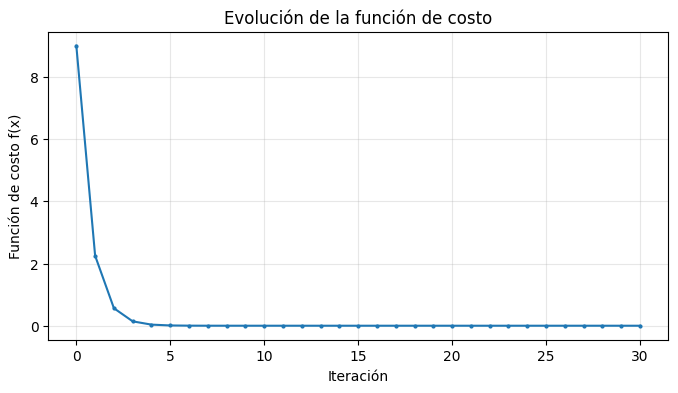

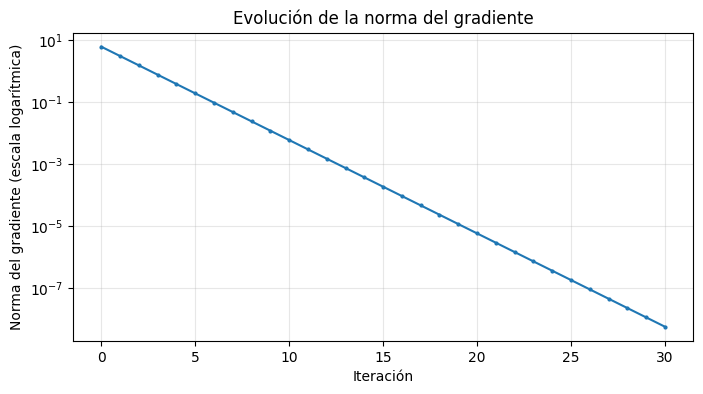

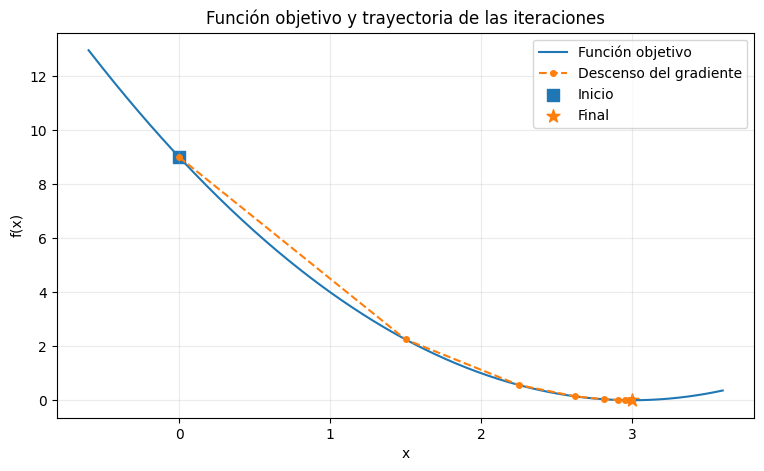

In [7]:
problema_ejemplo = ProblemaOptimizacion("(x-3)^2", "x")
problema_ejemplo.mostrar_funcion()
analitica_ejemplo = solucion_analitica(problema_ejemplo)
resultado_ejemplo = gradiente_descendente(
    problema_ejemplo, x0=[0], alpha=0.25, max_iter=100, tolerancia=1e-8
)
resumen_resultado(problema_ejemplo, resultado_ejemplo, analitica_ejemplo)
explicar_primeras_iteraciones(problema_ejemplo, resultado_ejemplo, cantidad=5)
graficar_convergencia(problema_ejemplo, resultado_ejemplo)

## 10. Comprobación de un paso inadecuado: $\alpha=1$

En el mismo ejercicio, al usar $\alpha=1$ aparece un ciclo. No basta con elegir cualquier tasa positiva: es necesario analizar la estabilidad o usar una estrategia adaptativa.

In [8]:
resultado_oscilacion = gradiente_descendente(
    problema_ejemplo, x0=[0], alpha=1.0, max_iter=12, tolerancia=1e-8
)
print("Resultado con tasa de aprendizaje alpha=1:")
resumen_resultado(problema_ejemplo, resultado_oscilacion)

Resultado con tasa de aprendizaje alpha=1:
ESTADO: Oscilación detectada (ciclo de periodo 2); cambia la tasa de aprendizaje.
Punto numérico final: {'x': np.float64(0.0)}
Costo final: 9.0
Norma del gradiente final: 6.0
Iteraciones calculadas: 2


,Iteración,x,df/dx,f(x),||gradiente||,Paso aplicado
0,0,0.0,-6.0,9.0,6.0,1.0
1,1,6.0,6.0,9.0,6.0,1.0
2,2,0.0,-6.0,9.0,6.0,NaN


## 11. Tu propio ejercicio: asistente de captura de valores

**Esta sección solicita datos al estudiante** (función, variables, valores iniciales, tasa y tolerancias). Al ejecutar la celda, escribe los datos en las preguntas que aparezcan.

Ejemplos de entrada:

| Tipo | Función | Variables | Valores iniciales | Tasa sugerida |
|---|---|---|---|---|
| Una variable | `(x-3)^2` | `x` | `0` | `0.25` |
| Dos variables | `(x-1)^2 + 3*(y+2)^2` | `x,y` | `4,3` | `0.1` |
| Tres variables | `(x-1)^2+(y+2)^2+(z-3)^2` | `x,y,z` | `5,4,0` | `0.2` |
| Rosenbrock (no convexa) | `100*(y-x^2)^2+(1-x)^2` | `x,y` | `-1.2,1` | `1` con retroceso |
| Función trigonométrica | `sin(x)+0.1*x^2` | `x` | `2` | `0.15` |

**Nota:** el solucionador analítico puede no encontrar todas las soluciones en funciones complejas o periódicas. La convergencia numérica depende de los valores y de la función elegidos.

Para introducir tus datos, ejecuta la celda siguiente. Si tu entorno no admite preguntas interactivas, puedes usar el **modo manual** de la sección 12.

In [9]:
def pedir_float(mensaje, por_defecto):
    entrada = input(f"{mensaje} [{por_defecto}]: ").strip()
    return float(entrada) if entrada else float(por_defecto)

def pedir_entero(mensaje, por_defecto):
    entrada = input(f"{mensaje} [{por_defecto}]: ").strip()
    return int(entrada) if entrada else int(por_defecto)

def pedir_texto(mensaje, por_defecto):
    entrada = input(f"{mensaje} [{por_defecto}]: ").strip()
    return entrada if entrada else por_defecto


def capturar_ejercicio():
    print("=== CAPTURA DE UN PROBLEMA DE OPTIMIZACIÓN ===")
    expresion = pedir_texto("Escribe la función f", "(x-3)^2")
    variables = pedir_texto("Variables separadas por comas", "x")
    problema = ProblemaOptimizacion(expresion, variables)
    texto_inicial = pedir_texto(
        f"Valores iniciales para ({', '.join(problema.nombres)}), separados por comas",
        ",".join(["0"] * problema.dimension)
    )
    inicial = [float(n.strip()) for n in texto_inicial.split(",")]
    if len(inicial) != problema.dimension:
        raise ValueError(f"Necesitas {problema.dimension} valores iniciales.")
    alpha = pedir_float("Tasa de aprendizaje alpha o beta", 0.25)
    max_iter = pedir_entero("Número máximo de iteraciones", 500)
    tolerancia = pedir_float("Tolerancia de la norma del gradiente", 1e-8)
    retroceso = pedir_texto("¿Activar retroceso de Armijo? (s/n)", "n").lower() in ("s", "si", "sí")
    return problema, inicial, alpha, max_iter, tolerancia, retroceso


def resolver_y_mostrar(problema, inicial, alpha=0.25, max_iter=500,
                      tolerancia=1e-8, retroceso=False):
    problema.mostrar_funcion()
    print("\n--- SOLUCIÓN ANALÍTICA ---")
    tabla_analitica = solucion_analitica(problema)
    print("\n--- SOLUCIÓN POR GRADIENTE DESCENDENTE ---")
    print("Punto inicial:", inicial, "| Tasa:", alpha,
          "| Retroceso Armijo:", retroceso)
    resultado = gradiente_descendente(problema, inicial, alpha, max_iter,
                                      tolerancia, retroceso)
    resumen_resultado(problema, resultado, tabla_analitica)
    explicar_primeras_iteraciones(problema, resultado, cantidad=5)
    graficar_convergencia(problema, resultado)
    return tabla_analitica, resultado

# Ejecútala para capturar valores interactivos.
# Si quieres evitar preguntas al ejecutar todas las celdas, cambia a False.
MODO_INTERACTIVO = False

if MODO_INTERACTIVO:
    try:
        problema_usuario, x0_usuario, alpha_usuario, maxiter_usuario, tol_usuario, armijo_usuario = capturar_ejercicio()
        analitica_usuario, resultado_usuario = resolver_y_mostrar(
            problema_usuario, x0_usuario, alpha_usuario,
            maxiter_usuario, tol_usuario, armijo_usuario
        )
    except (EOFError, KeyboardInterrupt):
        print("Captura cancelada o no disponible. Usa el modo manual de la siguiente sección.")
    except (ValueError, TypeError, SyntaxError) as ex:
        print("Verifica los datos introducidos:", ex)

## 12. Modo manual: cambia estos valores sin responder preguntas

Esta alternativa es útil para trabajar en clase, repetir experimentos rápidamente o cuando el entorno no admite `input()`.

**Modifica `funcion`, `variables`, `punto_inicial`, `alpha`, `max_iter`, `tolerancia` y `retroceso`**; luego ejecuta la celda.

FUNCIÓN OBJETIVO:


<IPython.core.display.Math object>

GRADIENTE SIMBÓLICO:


<IPython.core.display.Math object>

HESSIANA SIMBÓLICA:


<IPython.core.display.Math object>

... (5 outputs left out)

,Iteración,x,y,df/dx,df/dy,f(x),||gradiente||,Paso aplicado
0,0,4.000000,3.000000,6.000000,30.000000,84.000000,30.594117,0.1
1,1,3.400000,0.000000,4.800000,12.000000,17.760000,12.924396,0.1
2,2,2.920000,-1.200000,3.840000,4.800000,5.606400,6.146999,0.1
3,3,2.536000,-1.680000,3.072000,1.920000,2.666496,3.622649,0.1
4,4,2.228800,-1.872000,2.457600,0.768000,1.559101,2.574805,0.1
5,5,1.983040,-1.948800,1.966080,0.307200,0.974232,1.989935,0.1
6,6,1.786432,-1.979520,1.572864,0.122880,0.619734,1.577657,0.1
7,7,1.629146,-1.991808,1.258291,0.049152,0.396026,1.259251,0.1
8,8,1.503316,-1.996723,1.006633,0.019661,0.253360,1.006825,0.1
9,9,1.402653,-1.998689,0.805306,0.007864,0.162135,0.805345,0.1


Últimas 5 iteraciones:


,Iteración,x,y,df/dx,df/dy,f(x),||gradiente||,Paso aplicado
87,87,1.0,-2.0,2.223208e-08,0.0,1.235664e-16,2.223208e-08,0.1
88,88,1.0,-2.0,1.778566e-08,0.0,7.908247e-17,1.778566e-08,0.1
89,89,1.0,-2.0,1.422853e-08,0.0,5.061278e-17,1.422853e-08,0.1
90,90,1.0,-2.0,1.138283e-08,0.0,3.239218e-17,1.138283e-08,0.1
91,91,1.0,-2.0,9.106261e-09,0.0,2.073100e-17,9.106261e-09,NaN


Para ver la tabla completa, ejecuta: display(resultado['historial'])
Distancia al punto crítico analítico listado más cercano: 4.553130317219711e-09
Esta comparación no demuestra globalidad ni convergencia a un mínimo.

--- DESARROLLO PASO A PASO DE LAS PRIMERAS ACTUALIZACIONES ---
Iteración 0: costo f(x_0) = 84
  x_1 = 4 - (0.1)*(6) = 3.4
  y_1 = 3 - (0.1)*(30) = 0
  Costo nuevo: f(x_1) = 17.76
Iteración 1: costo f(x_1) = 17.76
  x_2 = 3.4 - (0.1)*(4.8) = 2.92
  y_2 = 0 - (0.1)*(12) = -1.2
  Costo nuevo: f(x_2) = 5.6064
Iteración 2: costo f(x_2) = 5.6064
  x_3 = 2.92 - (0.1)*(3.84) = 2.536
  y_3 = -1.2 - (0.1)*(4.8) = -1.68
  Costo nuevo: f(x_3) = 2.666496
Iteración 3: costo f(x_3) = 2.666496
  x_4 = 2.536 - (0.1)*(3.072) = 2.2288
  y_4 = -1.68 - (0.1)*(1.92) = -1.872
  Costo nuevo: f(x_4) = 1.55910144
Iteración 4: costo f(x_4) = 1.55910144
  x_5 = 2.2288 - (0.1)*(2.4576) = 1.98304
  y_5 = -1.872 - (0.1)*(0.768) = -1.9488
  Costo nuevo: f(x_5) = 0.974231962
... Se omiten los pasos res

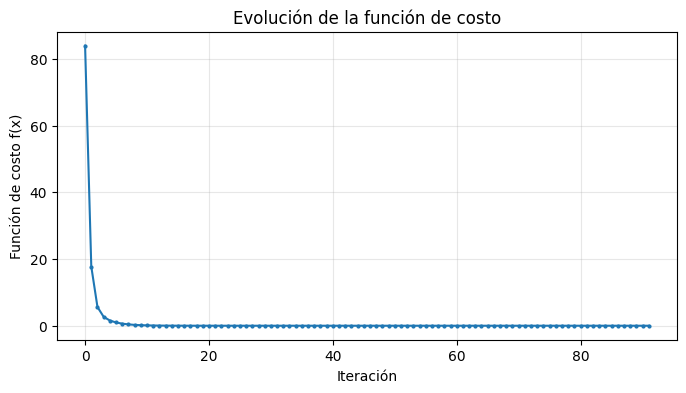

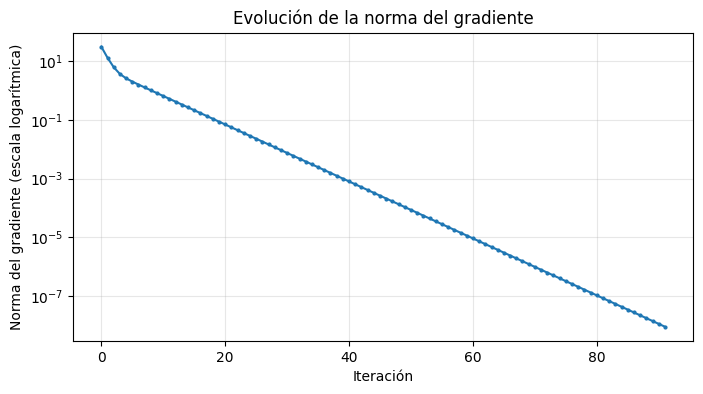

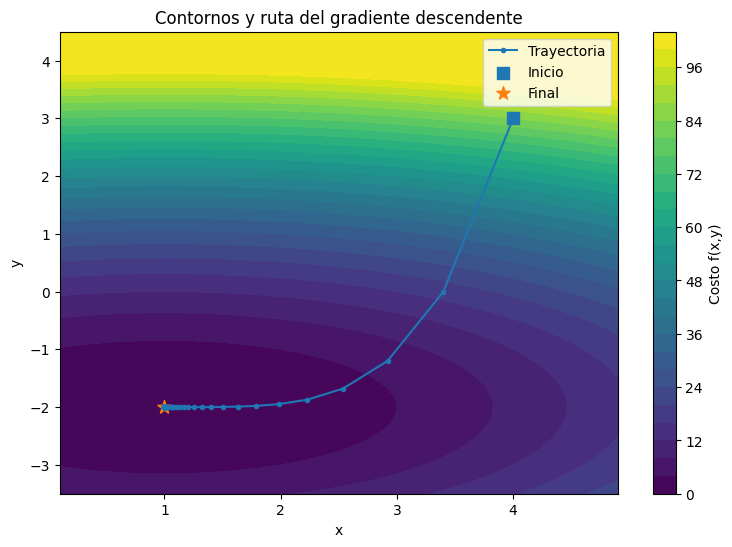

In [10]:
# ==============================================================
# EDITA LOS SIGUIENTES VALORES PARA RESOLVER TU PROPIO PROBLEMA
# ==============================================================
configuracion = {
    "funcion": "(x-1)^2 + 3*(y+2)^2",
    "variables": "x,y",
    "punto_inicial": [4.0, 3.0],
    "alpha": 0.10,
    "max_iter": 500,
    "tolerancia": 1e-8,
    "retroceso": False,
}

problema_manual = ProblemaOptimizacion(configuracion["funcion"], configuracion["variables"])
analitica_manual, resultado_manual = resolver_y_mostrar(
    problema_manual,
    configuracion["punto_inicial"],
    configuracion["alpha"],
    configuracion["max_iter"],
    configuracion["tolerancia"],
    configuracion["retroceso"],
)

### Exportar resultados (opcional)

Para guardar el historial completo en formato CSV, ejecuta esta instrucción en una celda nueva:

```python
resultado_manual["historial"].to_csv("iteraciones_gradiente_descendente.csv", index=False)
```

En Google Colab puedes descargar el archivo desde el panel **Archivos**. También puedes consultar la tabla completa con `display(resultado_manual["historial"])`.

## 13. Guía para interpretar los resultados

1. **Gradiente:** identifica las derivadas parciales y evalúa su valor en el punto inicial.
2. **Tabla de iteraciones:** revisa el valor de $f$ y las coordenadas después de cada actualización.
3. **Costo:** si usas paso fijo y los valores aumentan repetidamente, prueba una tasa menor o activa Armijo. No es obligatorio que cada paso fijo reduzca el costo.
4. **Norma del gradiente:** un valor cercano a cero indica **estacionariedad aproximada**, no necesariamente un mínimo global.
5. **Clasificación Hessiana:** compara la solución analítica de los puntos críticos con la trayectoria numérica. Una Hessiana semidefinida puede requerir un análisis adicional.
6. **Diferencias entre métodos:** la solución simbólica puede ser exacta; el gradiente descendente ofrece una aproximación numérica con error y tolerancias.

**Cálculo de error (si existe solución analítica conocida):**

$$\text{error de posición}=\|\mathbf{x}_{\mathrm{GD}}-\mathbf{x}^{*}\|_2.$$

Para funciones convexas diferenciables con condiciones apropiadas, la convergencia al mínimo puede justificarse matemáticamente. Para funciones no convexas, el inicio y la tasa pueden determinar a cuál mínimo local (o punto estacionario) se aproxima el método.

## 14. Actividades para practicar

**Actividad A — una variable.** Resuelve $f(x)=(x-5)^2+2$, comenzando en $x_0=-1$ con $\alpha=0.2$. ¿A qué valor tiende $x$? ¿Por qué el costo mínimo no es cero?

**Actividad B — dos variables.** Resuelve $f(x,y)=(x-2)^2+4(y+1)^2$, con $(x_0,y_0)=(5,4)$. Compara $\alpha=0.05$ y $\alpha=0.1$.

**Actividad C — inestabilidad.** Usa $f(x)=(x-3)^2$ y $x_0=0$. Ejecuta con $\alpha=0.25$, $\alpha=0.9$ y $\alpha=1$. Describe la diferencia entre convergencia y oscilación.

**Actividad D — función no convexa.** Prueba $f(x)=x^4-3x^2+2$ con valores iniciales negativos y positivos. ¿Converge siempre al mismo punto crítico?

**Actividad E — Rosenbrock.** Prueba $f(x,y)=100(y-x^2)^2+(1-x)^2$ con $(-1.2,1)$, `retroceso=True` y un número de iteraciones mayor. Compara con paso fijo. Explica por qué los valles estrechos dificultan la optimización.

### Preguntas de reflexión

- ¿Por qué el gradiente tiene signo contrario a la dirección de avance del algoritmo?
- ¿Por qué resolver $f'(x)=0$ no basta para demostrar un mínimo global?
- ¿Qué ocurre si el algoritmo se acerca a un punto de silla?
- ¿Qué diferencias existen entre **solución analítica**, **aproximación numérica** y **mínimo global demostrado**?

---

**Bibliografía recomendada para ampliar (consulta autónoma):** S. Boyd y L. Vandenberghe, *Convex Optimization* (2004), capítulos 3 y 9; J. Nocedal y S. J. Wright, *Numerical Optimization*, 2.ª ed. (2006), capítulos 2 y 3; I. Goodfellow, Y. Bengio y A. Courville, *Deep Learning* (2016), capítulo 8.